In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))
from lcoe import CostParams, system_cost, baseline_cost, cost_breakdown

import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import itertools
from itertools import chain, combinations

In [2]:
# Input and output paths
ROOT = Path().resolve().parent
RAW  = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
RESULTS = ROOT / 'results' 
FIG = RESULTS / 'figures'

In [3]:
raw_data = pd.read_csv(PROCESSED / "dataset_filtered.csv")
raw_data.info()
df = raw_data.copy()

<class 'pandas.DataFrame'>
RangeIndex: 2525 entries, 0 to 2524
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   well_id                2525 non-null   str    
 1   easting                2525 non-null   float64
 2   northing               2525 non-null   float64
 3   depth_tvd_m            2525 non-null   float64
 4   porosity_pct           2525 non-null   float64
 5   bulk_density_gcc       2525 non-null   float64
 6   formation_thickness_m  2525 non-null   float64
 7   distance_to_usp_km     2525 non-null   float64
 8   temp_harrison          2525 non-null   float64
 9   temp_res_c             2525 non-null   float64
 10  permeability_md        2525 non-null   float64
 11  k_log                  2525 non-null   float64
dtypes: float64(11), str(1)
memory usage: 236.8 KB


In [4]:
HEATING_TARGET = 10   #MW
COOLING_TARGET = 5    #MW

WELLS = df["well_id"].unique().tolist()

In [5]:
wells_base = {
    row["well_id"]: {
        "Easting" : row["easting"],
        "Northing":row["northing"],
        "Thickness": row["formation_thickness_m"],
        "Permeability": row["permeability_md"] * 9.869e-16,
        "Transmissivity": row["formation_thickness_m"] * row["permeability_md"] * 9.869e-16,
        "Temperature": row["temp_res_c"],
        "Depth": row["depth_tvd_m"]
    }
    for _, row in df.iterrows()
}

### Flow Rate and Thermal Power

$$\mu = 2.414 \times 10^{-5} \times 10^{\frac{247.8}{T + 133.15}}$$

$$Q=\frac{2\pi T\Delta P}{\mu (\ln (r_{e}/r_{w}) + S)}$$

$$ P_{th} = \dot{m}C_p(T_p - T_r)$$

In [6]:
def flow_rate_and_thermal_power(kh, T, T_r=40, rho_water=970, cp_water=4186, delta_p=18e5, r_e=1000, r_w=8 * 0.0254 / 2, skin=-1):
    """
    Calculates radial flow rate (q) and thermal power (P_th) for a water well.
    
    Parameters:
    kh        : Permeability-thickness product in m^3 (Transmissibility)
    T         : Temperature of the produced water in Celsius
    T_r       : Reinjection/reference temperature in Celsius (default: 40 C)
    rho_water : Density of water in kg/m^3 (default: 970)
    cp_water  : Specific heat capacity of water in J/(kg*K) (default: 4186)
    delta_p   : Pressure drawdown in Pascals (default: 1.8 MPa)
    r_e       : External/drainage radius in meters (default: 1000 m)
    r_w       : Wellbore radius in meters (default: 4 inches converted to meters)
    
    Returns:
    q         : Volumetric flow rate in m^3/s
    P_th_MW   : Thermal power in Megawatts (MW)
    """
    # Calculate dynamic viscosity of water as a function of temperature (Celsius)
    mu = 2.414e-5 * 10 ** (247.8 / (T + 133.15))

    # Radial flow rate using Darcy's Law
    q = (2 * np.pi * kh * delta_p) / (mu * (np.log(r_e / r_w) + skin))

    # Mass flow rate (kg/s)
    m_dot = rho_water * q
    T_p = T 

    # Thermal power in Watts, then converted to Megawatts
    P_th = m_dot * cp_water * (T_p - T_r)
    P_th_MW = P_th / 1e6

    return q, P_th_MW

In [7]:
def evaluate(well, power):
    gap = HEATING_TARGET - power
    if power > HEATING_TARGET:
        print(f"\n{well}meets both heating and cooling targets.\nTarget exceeded by {-gap:.2f} MW")
    elif power > COOLING_TARGET:
        print(f"\n{well} meets cooling target only.\n{gap:.2f} MW required to reach heating target.")
    else: 
        print(f"\n{well} does not meet heating or cooling target.\n{gap:.2f} MW required to reach heating target.")

    print(f"{well}'s thermal power is {power:.2f} MW")

### Modelling Thermal Interference

In [8]:
from scipy.special import exp1

# Constants
rho_w, g = 1000.0, 9.81
Ss, cw_vol, caq_vol = 1e-6, 4.18e6, 2.3e6   # specific storage, volumetric heat capacity of water, volumetric heat capacity of saturated rock
years = 30
t = years * 365.25 * 24 * 3600              # time in seconds

# Assumed inputs
Q = 150 / 3600   # m3/s 
D_SPACING = 1500         # m
az = {"BLT-01": 0.0, "JUT-01": 0.0}

# Building doublets
doub = {}
for name in wells_base:
    w = wells_base[name]
    a = np.radians(az[name])
    dx, dy = 0.5 * D_SPACING * np.cos(a), 0.5 * D_SPACING * np.sin(a)
    doub[name] = {"prod": (w["Easting"]-dx, w["Northing"]-dy, + Q),
                  "inj": (w["Easting"]+dx, w["Northing"]+dy, -Q)}

$$\text{Thermal Radius}$$
$$R_{th}=\sqrt {\frac{Q t c_{w}}{\pi H c_{aq}}}$$

$$\text{Thermal Breakthrough Time (Gringarten-type doublet model)}$$
$$t_{b}=t_{w} \cdot \frac{c_{aq}}{\phi c_{w}} = \frac{\pi d^{_2} H c_{aq}}{3 Q c_{w}}$$

In [9]:
# Thermal checks between producer-injector
for name in wells_base:
    w = wells_base[name]
    R_th = np.sqrt(Q * t * cw_vol/ (np.pi * w["Thickness"] * caq_vol))
    t_b = np.pi * D_SPACING ** 2 * w["Thickness"] * caq_vol / (3 * Q * cw_vol) / (365 * 24 * 3600)
    print(f"\n{name}"
          f"\nCold front advances by {R_th:.0f} m after 30 years"
          f"\nd/2 = {D_SPACING/2} m"
          f"\nBreakthrough will be in {t_b:.0f} years")


BLT-01
Cold front advances by 432 m after 30 years
d/2 = 750.0 m
Breakthrough will be in 121 years

JUT-01
Cold front advances by 426 m after 30 years
d/2 = 750.0 m
Breakthrough will be in 124 years


$$\text{Theis Solution}$$
$$\Delta T(r, t)=\frac{q}{4 \pi k} E{_1}(\frac{r^{2}}{4 \alpha t})$$

In [10]:
# Averaged properties
props = {}
for name in wells_base:
    w = wells_base[name]
    mu_water = 2.414e-5 * 10 ** (247.8 / (w["Temperature"] + 273.15 - 140))
    K = w["Permeability"] * rho_w * g / mu_water
    props[name] = {"T": K * w["Thickness"], "S": Ss * w["Thickness"]}

Th = np.sqrt(props["BLT-01"]["T"] * props["JUT-01"]["T"])
S  = 0.5 * (props["BLT-01"]["S"] + props["JUT-01"]["S"])    
print(f"Th = {Th:.2e} m2/s, S = {S:.2e}")

Th = 1.85e-04 m2/s, S = 1.24e-04


In [11]:
# Checking pressure interference
for src, tgt in [("BLT-01", "JUT-01"), ("JUT-01", "BLT-01")]:
    for role, (xt, yt, _) in doub[tgt].items():
        s = 0.0                        
        for xs, ys, q in doub[src].values():
            r = np.hypot(xt - xs, yt - ys)
            s += q / (4 * np.pi * Th) * exp1(r**2 * S / (4 * Th * t))
        print(f"{src} -> {tgt} {role}: {s:+.2f} m ({s*rho_w*g/1e5:+.3f} bar)")

BLT-01 -> JUT-01 prod: +4.62 m (+0.453 bar)
BLT-01 -> JUT-01 inj: +4.97 m (+0.488 bar)
JUT-01 -> BLT-01 prod: -4.97 m (-0.488 bar)
JUT-01 -> BLT-01 inj: -4.62 m (-0.453 bar)


In [12]:
L = np.hypot(wells_base["BLT-01"]["Easting"] - wells_base["JUT-01"]["Easting"],
             wells_base["BLT-01"]["Northing"] - wells_base["JUT-01"]["Northing"])

# Nearest well-to-well distance between the two doublets
d_min = min(np.hypot(x1 - x2, y1 - y2)
            for x1, y1, _ in doub["BLT-01"].values()
            for x2, y2, _ in doub["JUT-01"].values())

print(f"Doublet centre spacing: {L:.0f} m")
print(f"Nearest wells:          {d_min:.0f} m")

for name in wells_base:
    H = wells_base[name]["Thickness"]
    R_th = np.sqrt(Q * t * cw_vol / (np.pi * H * caq_vol))
    print(f"\n{name}: front = {R_th:.0f} m, {R_th/d_min*100:.1f}% of the nearest-well distance")
    t_reach = np.pi * H * d_min**2 * caq_vol / (Q * cw_vol) / (365.25 * 24 * 3600)
    print(f"{name}: front reaches the nearest well of the other doublet in {t_reach:,.0f} years")

Doublet centre spacing: 9084 m
Nearest wells:          7895 m

BLT-01: front = 432 m, 5.5% of the nearest-well distance
BLT-01: front reaches the nearest well of the other doublet in 10,029 years

JUT-01: front = 426 m, 5.4% of the nearest-well distance
JUT-01: front reaches the nearest well of the other doublet in 10,305 years


**Result**
- The doublets do not interfere thermally. 
- They interfere hydraulically but only slightly

## Production Scenarios

### 1. One Doublet

In [13]:
q_blt_base, p_blt_base = flow_rate_and_thermal_power(kh=wells_base["BLT-01"]["Transmissivity"], T=wells_base["BLT-01"]["Temperature"])
q_jut_base, p_jut_base = flow_rate_and_thermal_power(kh=wells_base["JUT-01"]["Transmissivity"], T=wells_base["JUT-01"]["Temperature"])

print("===BaseCase Power===")
print(f"Heating Target = {HEATING_TARGET} MW")
print(f"Cooling Target = {COOLING_TARGET} MW")
evaluate("BLT-01", p_blt_base)
evaluate("JUT-01", p_jut_base)

===BaseCase Power===
Heating Target = 10 MW
Cooling Target = 5 MW

BLT-01 meets cooling target only.
3.75 MW required to reach heating target.
BLT-01's thermal power is 6.25 MW

JUT-01 does not meet heating or cooling target.
7.79 MW required to reach heating target.
JUT-01's thermal power is 2.21 MW


 **Result**
- In order to meet our heating target, we need an increase in thermal power.
- An increase in thermal power by can be achieved by boosting flow rate by via stimulation, or by lowering the reinjection temperature.
- Cooling is a separate surface plant. 
- Our design runs on the assumption that heating and cooling do not happen simultaneously

### 2. Well Interventions: Heating

In [14]:
interventions = {
    "none":           dict(skin=-1, T_r=30, hp=False),
    "thermogis_stim": dict(skin=-4, T_r=30, hp=False),
    "heat_pump":      dict(skin=-1, T_r=20,   hp=True),    
    "stim_hp":        dict(skin=-4, T_r=20,   hp=True),
}

#### Transmissivity Uncertainty Analysis

In [15]:
therm_ds = pd.read_csv(PROCESSED / "thermogis_long.csv")
therm_ds = therm_ds[therm_ds["Well_ID"].isin(WELLS)]

# Pivoting transmissivity
trans = (therm_ds[therm_ds["Property"] == "Transmissivity"]
         .pivot_table(index="Well_ID", columns="Probability", values="Value", aggfunc="first"))
print(trans)

# Log-normal uncertainty calculation
sig_by_well = {w: np.log(trans.loc[w, "P10"] / trans.loc[w, "P90"]) / (2 * 1.2816) for w in WELLS}
print(f"\nUncertainty by well:")
print({w: round(s, 2) for w, s in sig_by_well.items()})

Probability   P10  P50  P90
Well_ID                    
BLT-01       66.1  9.3  1.3
JUT-01       10.4  4.8  2.2

Uncertainty by well:
{'BLT-01': np.float64(1.53), 'JUT-01': np.float64(0.61)}


**Result**
- BLT-01 (High Uncertainty $\sigma = 1.53$)
    - Shows a massive spread between its low case ($1.3$) and high case ($66.1$)
    - A high log-standard deviation indicates significant subsurface heterogeneity or uncertainty in transmissivity.
- JUT-01 (Lower Uncertainty $\sigma = 0.61$)
    - Much more tightly constrained, ranging from $2.2$ (P90) to $10.4$ (P10)
    - Reflects a more predictable or well-defined formation.

#### Monte Carlo Simulation

In [16]:
N = 10_000
DM_TO_M3 = 9.869e-13
Q_pump_max = 250 /3600       # m3/s per doublet
COP_hp = 5.0
rng_mc = np.random.default_rng(42)

def well_subsets(wells):
    return chain.from_iterable(combinations(wells, r) for r in range(1, len(wells) + 1))

def summarize_p10_p50_p90(values):
    """Reservoir convention: P10 = high case (90th percentile), P90 = low case (10th percentile)."""
    return {"P10_high": np.percentile(values, 90), 
            "P50_median": np.percentile(values, 50),
            "P90_low": np.percentile(values, 10), 
            "mean": np.mean(values), 
            "std": np.std(values)}

def sample_transmissivity_m3(p90, p50, p10, n):
    """Lognormal fitted to ThermoGIS P90/P50/P10 (Dm), returned in m3."""
    sigma = np.log(p10 / p90) / (2 * 1.2816)
    return rng_mc.lognormal(np.log(p50), sigma, n) * DM_TO_M3

def mc_power(well, method, kh):
    """Heat delivered (MW) for an array of transmissivity draws."""
    iv = interventions[method]
    q, p = flow_rate_and_thermal_power(kh=kh, T=wells_base[well]["Temperature"],
                                       T_r=iv["T_r"], skin=iv["skin"])
    p = p * np.minimum(q, Q_pump_max) / q
    return p * COP_hp / (COP_hp - 1) if iv["hp"] else p

In [17]:
# Transmissivity sampling
kh = {w: sample_transmissivity_m3(trans.loc[w, "P90"], trans.loc[w, "P50"], trans.loc[w, "P10"], N)
      for w in WELLS}

# Grid Search
rows = []
for subset in well_subsets(WELLS):
    for combo in itertools.product(interventions.keys(), repeat=len(subset)):
        detail = {}
        total_power = np.zeros(N)     

        for well, method in zip(subset, combo):
            p = mc_power(well, method, kh[well])      
            detail[well] = method     
            total_power += p

        for well in WELLS:                                
            if well not in subset:
                detail[well] = "not_drilled"

        st = summarize_p10_p50_p90(total_power)
        detail["P_meet_10MW"] = (total_power >= HEATING_TARGET).mean()
        detail["P10_high_MW"] = st["P10_high"]
        detail["P50_MW"] = st["P50_median"]
        detail["P90_low_MW"] = st["P90_low"]
        rows.append(detail)

mc_grid = pd.DataFrame(rows).round(2).sort_values("P_meet_10MW", ascending=False)
mc_grid.to_csv(RESULTS / "montecarlo_results.csv", index=False)
mc_grid.round(2)

,BLT-01,JUT-01,P_meet_10MW,P10_high_MW,P50_MW,P90_low_MW
23,stim_hp,stim_hp,0.87,32.49,23.76,9.10
15,thermogis_stim,stim_hp,0.82,25.79,17.74,7.83
19,heat_pump,stim_hp,0.81,31.23,19.84,7.70
21,stim_hp,thermogis_stim,0.80,28.28,22.02,6.89
22,stim_hp,heat_pump,0.80,28.25,22.11,6.82
11,none,stim_hp,0.75,24.73,16.27,6.74
20,stim_hp,none,0.74,25.61,20.38,5.42
13,thermogis_stim,thermogis_stim,0.73,21.36,15.70,5.93
14,thermogis_stim,heat_pump,0.72,21.45,15.79,5.87
17,heat_pump,thermogis_stim,0.72,27.38,16.28,5.83


**Result**
1. Applying stimulation combined with a heat pump (stim_hp) on both wells (BLT-01 and JUT-01) is the optimal configuration. It gives an 87% chance of meeting the $10\text{ MW}$ heating target, a robust median output of $23.76\text{ MW}$, and even a conservative P90 low case of $9.10\text{ MW}$ (which is right on the doorstep of the target).
2. Strategies that rely on doing nothing (none) or leaving a well un-drilled (not_drilled) drop the success probability down into the 40%–50% range or lower. Stimulation and heat pump boosts are critical for clearing the $10\text{ MW}$ threshold reliably.
3. Shifting BLT-01's intervention from stim_hp down to thermogis_stim or heat_pump drops the success rate by 5–6 percentage points, showing that BLT-01 plays a heavily dominant role in meeting the project's energy target.

### 3. Surface Interventions: Cooling

In [18]:
# Electric chiller
COOLING = "electric"
COP_ch = 4.5
dT_cool = 6.0                 # temperature difference across the cooling loop

# ATES (shallow aquifer storage) cooling
Q_ates = 200 / 3600           # m3/s
COP_ates = 20.0
ATES_RECOVERY = 0.0                                                 # hours per month

#### Design Assumptions

In [19]:
# Energy Demand and Demand Profiles
heat_peak, cool_peak = HEATING_TARGET, COOLING_TARGET      # MW
LOAD_FACTOR_HEAT, LOAD_FACTOR_COOL = 0.43, 0.2
heat_MW = np.full(12, heat_peak * LOAD_FACTOR_HEAT)        
cool_MW = np.full(12, cool_peak * LOAD_FACTOR_COOL)
hrs = 730

# Reservoir and Well Design Parameters
T_inj_base, T_inj_hp = 30.0, 20.0
skin_base, skin_stim = -1.0, -4.0
eta_pump, rw = 0.6, 0.108                             # Pump efficiency; 8.5 inch well
sig_lnk = 0.5
YEAR_S = 365.25 * 24 * 3600
t30 = 30 * YEAR_S

# Economic and Financial Parameters
COST = CostParams()
print(f"Financing: {1 - COST.equity_share:.0%} loan at {COST.loan_rate:.0%}, equity return {COST.equity_return:.0%}, inflation {COST.inflation:.0%}, lifetime {COST.lifetime} years")

Financing: 80% loan at 5%, equity return 7%, inflation 2%, lifetime 30 years


## System Design

In [20]:
ORDER = sorted(WELLS, key=lambda w: -wells_base[w]["Transmissivity"])
demand, cool = heat_MW, cool_MW

def mu_w(T): return 2.414e-5 * 10 ** (247.8 / (T + 273.15 - 140))

def design_wells(w, stim, hp, dP_bar, d_floor=500.0):
    """
    Individual well and doublet sizing
    Computes hydraulic performance(Q), thermal breakthrough spacing(d) and power output(P_src)
    """
    T_inj = T_inj_hp if hp else T_inj_base
    skin = skin_stim if stim else skin_base
    Tp, H, k = w["Temperature"], w["Thickness"], w["Permeability"]
    Kp = k * rho_w * g / mu_w(Tp)
    Ki = k * rho_w * g / mu_w(T_inj)

    def flow(dd):
        res_ = (np.log(dd / rw) + skin) * (1 / (Kp * H) + 1 / (Ki * H)) / (2 * np.pi)
        return res_, min(dP_bar * 1e5 / (rho_w * g) / res_, Q_pump_max)
    
    dd = D_SPACING
    res_, Q = flow(dd)
    dP = Q * res_ * rho_w * g
    return dict(Q=Q, d=dd, P_src=cw_vol * Q * (Tp - T_inj) / 1e6, P_pump=Q * dP / eta_pump / 1e6)

def design_system(wells, stim, hp, dP_bar, cooling=None):
    """
    System-wide energy and peak balancing
    Aggregates capacity, backup heating and cooling infrastructure
    """
    cooling = cooling or COOLING
    ds = [design_wells(w, stim, hp, dP_bar) for w in wells.values()]
    P_src, P_pump = sum(x["P_src"] for x in ds), sum(x["P_pump"] for x in ds)
    P_w = P_src * COP_hp / (COP_hp - 1) if hp else P_src

    backup_MW = max(heat_peak - P_w, 0.0)                     # boiler covers what the wells cannot at 10 MW
    if cooling == "ates":
        n_ates, chiller_MW = int(np.ceil(cool_peak * 1e6 / (cw_vol * dT_cool) / Q_ates)), 0.0
    else:
        n_ates, chiller_MW = 0, cool_peak                     # electric chillers sized for 5 MW

    # annual operation at the average load (wells run as baseload)
    wells_MW = np.minimum(P_w, demand)
    util = wells_MW / P_w
    E_wells, E_heat = wells_MW.sum() * hrs, demand.sum() * hrs
    E_cool = cool.sum() * hrs
    el_wells = (P_pump * util).sum() * hrs + (wells_MW.sum() * hrs / COP_hp if hp else 0.0)
    el_cool = E_cool / (COP_ates if cooling == "ates" else COP_ch)

    return dict(wells=wells, stim=stim, hp=hp, cooling=cooling, dP_bar=dP_bar,
                Q_m3h=sum(x["Q"] for x in ds) * 3600, d_m=np.mean([x["d"] for x in ds]),
                P_wells_MW=P_w, backup_MW=backup_MW, chiller_MW=chiller_MW, n_ates=n_ates,
                E_wells=E_wells, E_gas=E_heat - E_wells, E_heat=E_heat, E_cool=E_cool,
                el_wells=el_wells, el_cool=el_cool, share=E_wells / E_heat,
                meets_peak_alone=P_w >= heat_peak, cool_MW=cool_peak)

def scenario(wells, stim, hp, dP_bar, cooling=None):
    """
    Merges technical design with Cost Functions
    """
    D = design_system(wells, stim, hp, dP_bar, cooling)
    return {**{k: v for k, v in D.items() if k != "wells"}, **system_cost(D, COST)}

rng_sc = np.random.default_rng(42)
def sample(wells):
    return {n_: {**w,
                 "Permeability": w["Permeability"] * rng_sc.lognormal(0, sig_by_well.get(n_, sig_lnk)),
                 "Temperature": w["Temperature"] + rng_sc.normal(0, 2),
                 "Thickness": w["Thickness"] * rng_sc.normal(1, 0.05)}
            for n_, w in wells.items()}

In [21]:
rows = []

for dP, n_wells, stim, hp in itertools.product([18, 30, 45, 60], [1, 2], [False, True], [False, True]):
    wells = {k: wells_base[k] for k in ORDER[:n_wells]}
    b = scenario(wells, stim, hp, dP)
    mc = pd.DataFrame([scenario(sample(wells), stim, hp, dP) for _ in range(300)])
    rows.append(dict(dP_bar=dP, doublets=n_wells, stim=stim, hp=hp,
                     Q_m3h=b["Q_m3h"], d_m=b["d_m"], P_wells_MW=b["P_wells_MW"],
                     backup_MW=b["backup_MW"], heat_share=b["share"], capex_M=b["capex_M"],
                     LCOE_system=b["LCOE_system"],
                     LCOE_P10=mc.LCOE_system.quantile(.1), LCOE_P90=mc.LCOE_system.quantile(.9),
                     P_wells_alone_ge_10MW=(mc.P_wells_MW >= heat_peak).mean()))
scen_table = pd.DataFrame(rows)

# Filtering for scenarios that meet heating target 50 % of the time
filtered_scen = scen_table[scen_table["P_wells_alone_ge_10MW"] >= 0.5].round(2).sort_values("capex_M", ascending=True)
filtered_scen.to_csv(RESULTS / "scenarios_cost.csv", index=False)

# baseline for the same system: gas boiler for heat + electric chillers for cooling
E_h, E_c = demand.sum() * hrs, cool.sum() * hrs
print(f"\nGas + electric chillers, whole system: {baseline_cost(E_h, E_c, heat_peak, cool_peak, COP_ch, COST):.0f} EUR/MWh")
filtered_scen


Gas + electric chillers, whole system: 68 EUR/MWh


,dP_bar,doublets,stim,hp,Q_m3h,d_m,P_wells_MW,backup_MW,heat_share,capex_M,LCOE_system,LCOE_P10,LCOE_P90,P_wells_alone_ge_10MW
26,60,1,True,False,211.06,1500.0,12.17,0.00,1.0,23.29,69.18,55.73,81.18,0.53
19,45,1,True,True,134.39,1500.0,11.64,0.00,1.0,25.39,91.86,74.25,123.58,0.58
27,60,1,True,True,179.19,1500.0,15.52,0.00,1.0,27.84,104.61,75.40,124.30,0.62
28,60,2,False,False,203.17,1500.0,11.07,0.00,1.0,37.02,92.43,81.86,109.57,0.59
14,30,2,True,False,156.61,1500.0,8.53,1.47,1.0,37.07,86.45,80.73,109.12,0.51
22,45,2,True,False,234.91,1500.0,12.80,0.00,1.0,38.77,96.94,81.79,113.78,0.62
21,45,2,False,True,129.59,1500.0,10.71,0.00,1.0,39.00,114.57,99.01,160.31,0.54
15,30,2,True,True,133.18,1500.0,11.00,0.00,1.0,40.19,116.42,99.42,163.33,0.56
30,60,2,True,False,313.22,1500.0,17.07,0.00,1.0,40.61,107.67,84.83,117.68,0.75
29,60,2,False,True,172.78,1500.0,14.27,0.00,1.0,41.26,126.38,101.17,165.70,0.71


## Chosen Design

In [22]:
CHOICE = dict(n_wells=1, stim=True, hp=False, dP_bar=60, cooling="electric")

wells = {k: wells_base[k] for k in ORDER[:CHOICE["n_wells"]]}
D = design_system(wells, CHOICE["stim"], CHOICE["hp"], CHOICE["dP_bar"], CHOICE["cooling"])

print("=== DESIGN ===")
print(f"Doublets:              {list(wells)}  (stimulated: {CHOICE['stim']}, heat pump: {CHOICE['hp']})")
print(f"Well flow:             {D['Q_m3h']:.0f} m3/h, spacing {D['d_m']:.0f} m")
print(f"Geothermal heat:       {D['P_wells_MW']:.1f} MW  (target {heat_peak} MW)")
print(f"Backup boiler:         {D['backup_MW']:.1f} MW  -> heat at peak = {D['P_wells_MW'] + D['backup_MW']:.1f} MW")

if D["cooling"] == "ates":
    print(f"Cooling plant:         {D['n_ates']} ATES doublets for {cool_peak} MW")
else:
    print(f"Cooling plant:         {D['chiller_MW']:.1f} MW electric chillers for {cool_peak} MW")
print(f"Annual heat / cooling: {D['E_heat']/1e3:.1f} / {D['E_cool']/1e3:.1f} GWh, geothermal share of heat {D['share']:.0%}")

C = system_cost(D, COST)
print("\n=== COST (whole system) ===")
print(f"Capex:                 {C['capex_M']:.1f} MEUR  {({k: round(float(v), 1) for k, v in C['capex_split_M'].items()})}")
print(f"Revenue needed:        {C['annual_M']:.2f} MEUR/yr (flat, nominal) for {C['useful_GWh']:.1f} GWh/yr of heat + cooling")
print(f"LCOE, whole system:    {C['LCOE_system']:.0f} EUR/MWh")

E_h, E_c = demand.sum() * hrs, cool.sum() * hrs
price = baseline_cost(E_h, E_c, heat_peak, cool_peak, COP_ch, COST)    # EUR/MWh, replace with a real tariff if you have one
C = system_cost(D, COST, sell_price=price)

pb = lambda v: "not within the project life" if v is None else f"{v:.1f} years"
print(f"Selling price: {price:.0f} EUR/MWh")
print(f"Equity payback: simple {pb(C['payback_years'])} | discounted {pb(C['payback_discounted_years'])}")

=== DESIGN ===
Doublets:              ['BLT-01']  (stimulated: True, heat pump: False)
Well flow:             211 m3/h, spacing 1500 m
Geothermal heat:       12.2 MW  (target 10 MW)
Backup boiler:         0.0 MW  -> heat at peak = 12.2 MW
Cooling plant:         5.0 MW electric chillers for 5 MW
Annual heat / cooling: 37.7 / 8.8 GWh, geothermal share of heat 100%

=== COST (whole system) ===
Capex:                 23.3 MEUR  {'geothermal': 21.8, 'backup': 0.0, 'cooling': 1.5}
Revenue needed:        3.21 MEUR/yr (flat, nominal) for 46.4 GWh/yr of heat + cooling
LCOE, whole system:    69 EUR/MWh
Selling price: 68 EUR/MWh
Equity payback: simple 12.0 years | discounted 16.7 years


## Monte Carlo Simulation for Chosen Design

In [23]:
sig_saved = sig_lnk
sig_lnk = np.log(trans.loc[ORDER[0], "P10"] / trans.loc[ORDER[0], "P90"]) / (2 * 1.2816)
print(f"Uncertainty of ln(k) = {sig_lnk:.2f}")

N_MC = 2000
rng_sc = np.random.default_rng(1)
draws = []
for _ in range(N_MC):
    D_s = design_system(sample(wells), CHOICE["stim"], CHOICE["hp"], CHOICE["dP_bar"], CHOICE["cooling"])
    C_s = system_cost(D_s, COST)
    draws.append(dict(P_wells_MW=D_s["P_wells_MW"], backup_MW=D_s["backup_MW"],
                      heat_share=D_s["share"], capex_M=C_s["capex_M"], LCOE=C_s["LCOE_system"]))
sig_lnk = sig_saved        
mc_sys = pd.DataFrame(draws)

x = mc_sys["P_wells_MW"].values                  
st = summarize_p10_p50_p90(x)

print(f"P(wells alone >= {HEATING_TARGET} MW): {(x >= HEATING_TARGET).mean():.0%}")
print(f"Wells power: median {st['P50_median']:.1f} MW | conservative (P90) {st['P90_low']:.1f} MW")
print(f"Backup needed to cover 90% of draws: {mc_sys.backup_MW.quantile(0.90):.1f} MW")
print(f"System LCOE (EUR/MWh): low {mc_sys.LCOE.quantile(.1):.0f} | median {mc_sys.LCOE.median():.0f} | high {mc_sys.LCOE.quantile(.9):.0f}")

Uncertainty of ln(k) = 1.53
P(wells alone >= 10 MW): 56%
Wells power: median 12.7 MW | conservative (P90) 1.7 MW
Backup needed to cover 90% of draws: 8.3 MW
System LCOE (EUR/MWh): low 56 | median 71 | high 79


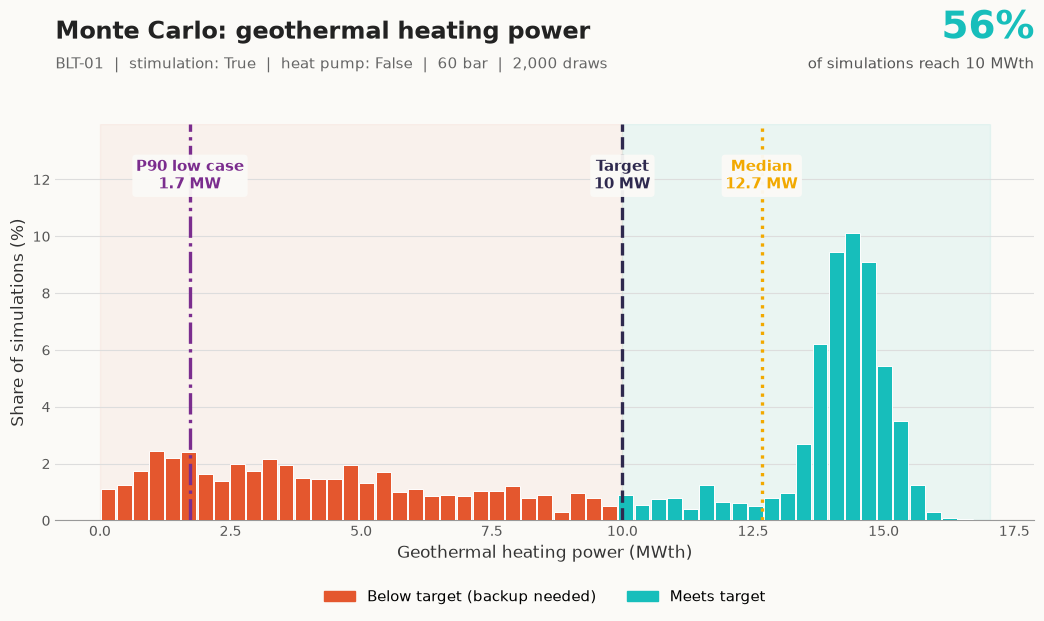

In [24]:
from matplotlib.patches import Patch

C_BELOW, C_ABOVE = "#E4572E", "#17BEBB"                 # below / above target
C_TARGET, C_MED, C_P90, C_BG = "#2E294E", "#F2A900", "#7B2D8E", "#FBFAF7"

p_meet = (x >= HEATING_TARGET).mean()
counts, edges = np.histogram(x, bins=np.linspace(0, x.max() * 1.02, 56))
centers, widths = (edges[:-1] + edges[1:]) / 2, np.diff(edges)
pct = counts / len(x) * 100                              # % of simulations per bin

fig, ax = plt.subplots(figsize=(11, 6.6))
fig.patch.set_facecolor(C_BG); ax.set_facecolor(C_BG)
fig.subplots_adjust(top=0.80, bottom=0.20, left=0.08, right=0.97)

ax.bar(centers, pct, width=widths * 0.92,
       color=np.where(centers >= HEATING_TARGET, C_ABOVE, C_BELOW),
       edgecolor="white", linewidth=0.7, zorder=3)
ax.axvspan(HEATING_TARGET, edges[-1], color=C_ABOVE, alpha=0.07, zorder=0)
ax.axvspan(edges[0], HEATING_TARGET, color=C_BELOW, alpha=0.05, zorder=0)

top = pct.max()
ax.set_ylim(0, top * 1.38)
for val, col, ls, label in [
        (st["P90_low"],    C_P90,    "-.", f"P90 low case\n{st['P90_low']:.1f} MW"),
        (HEATING_TARGET,   C_TARGET, "--", f"Target\n{HEATING_TARGET} MW"),
        (st["P50_median"], C_MED,    ":",  f"Median\n{st['P50_median']:.1f} MW")]:
    ax.axvline(val, color=col, linestyle=ls, linewidth=2.4, zorder=4)
    ax.text(val, top * 1.14, label, color=col, ha="center", va="bottom", fontsize=10.5,
            fontweight="bold", zorder=5,
            bbox=dict(boxstyle="round,pad=0.25", facecolor=C_BG, edgecolor="none", alpha=0.95))

# headline above the plot
fig.text(0.08, 0.93, "Monte Carlo: geothermal heating power", fontsize=17, fontweight="bold", color="#222")
fig.text(0.08, 0.885, f"{', '.join(wells)}  |  stimulation: {CHOICE['stim']}  |  heat pump: {CHOICE['hp']}  |  "
         f"{CHOICE['dP_bar']} bar  |  {len(x):,} draws", fontsize=10.5, color="#666")
fig.text(0.97, 0.93, f"{p_meet:.0%}", fontsize=28, fontweight="bold", color=C_ABOVE, ha="right")
fig.text(0.97, 0.885, f"of simulations reach {HEATING_TARGET} MWth", fontsize=10.5, color="#555", ha="right")

ax.set_xlabel("Geothermal heating power (MWth)", fontsize=12, color="#333")
ax.set_ylabel("Share of simulations (%)", fontsize=12, color="#333")
ax.grid(axis="y", color="#DDD", linewidth=0.8, zorder=1)
for sp in ["top", "right", "left"]: ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_color("#999"); ax.tick_params(colors="#555", length=0)
ax.legend(handles=[Patch(color=C_BELOW, label="Below target (backup needed)"),
                   Patch(color=C_ABOVE, label="Meets target")],
          loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, fontsize=11)
plt.show()
fig.savefig(FIG / "chosen_scenario_mc.png", dpi=200, bbox_inches="tight")

## Doublet Site and Radius Map

In [25]:
# Utrecht Boundaries
utrecht_province = gpd.read_file(PROCESSED /"utrecht_province.gpkg")
utrecht_city = gpd.read_file(PROCESSED / "utrecht_city.gpkg")

# Utrecht Province Clip
X_MIN, X_MAX = 110_000, 175_000 
Y_MIN, Y_MAX = 430_000, 480_000

# Slochteren Formation Grid 
nc_path = RAW / "ROSL_ROSLU_depth.nc"
ds = xr.open_dataset(nc_path)

# Coordinates
x_var = [c for c in ds.coords if c.lower() in ("x", "xrdr", "easting")][0]
y_var = [c for c in ds.coords if c.lower() in ("y", "rdy", "northing")][0]
z_var = list(ds.data_vars)[0] 

X = ds[x_var].values
Y = ds[y_var].values
Z = ds[z_var].values

# BLT-01 Doublet Coordinates
prod_x, prod_y = doub["BLT-01"]["prod"][0], doub["BLT-01"]["prod"][1]
inj_x, inj_y = doub["BLT-01"]["inj"][0], doub["BLT-01"]["inj"][1]

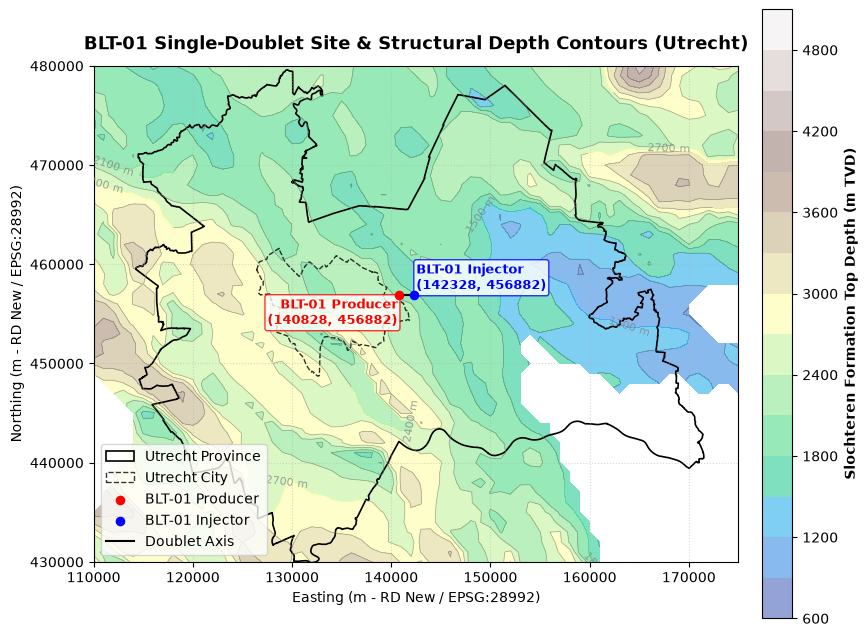

In [26]:
fig, ax = plt.subplots(figsize=(9, 9))

# Contours
contour_levels = 15
cf = ax.contourf(X, Y, Z, levels=contour_levels, cmap="terrain", alpha=0.5)
cs = ax.contour(X, Y, Z, levels=contour_levels, colors="grey", linewidths=0.5, alpha=0.7)
ax.clabel(cs, inline=True, fontsize=8, fmt="%d m")

cbar = fig.colorbar(cf, ax=ax, shrink=0.7, pad=0.03)
cbar.set_label("Slochteren Formation Top Depth (m TVD)", fontsize=10, fontweight="bold")

# GIS administrative boundaries
utrecht_province.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.2, label="Utrecht Province")
utrecht_city.plot(ax=ax, facecolor="none", edgecolor="black", linestyle="--", linewidth=1.0, alpha=0.8, label="Utrecht City")

# BLT-01 Geothermal Doublet
ax.scatter([prod_x], [prod_y], color='red', s=35, label='BLT-01 Producer', zorder=5)
ax.scatter([inj_x], [inj_y], color='blue', s=35, label='BLT-01 Injector', zorder=5)
ax.plot([prod_x, inj_x], [prod_y, inj_y], color='black', linewidth=1.5, linestyle='-', label='Doublet Axis')

# Annotations
ax.text(prod_x - 200, prod_y - 200, 'BLT-01 Producer\n(140828, 456882)', fontsize=9, ha="right", va='top', fontweight='bold', color='red', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='red'))
ax.text(inj_x + 200, inj_y + 200, 'BLT-01 Injector\n(142328, 456882)', fontsize=9, ha='left', va='bottom', fontweight='bold', color='blue', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='blue'))

# 6. Map Formatting
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_title("BLT-01 Single-Doublet Site & Structural Depth Contours (Utrecht)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Easting (m - RD New / EPSG:28992)", fontsize=10)
ax.set_ylabel("Northing (m - RD New / EPSG:28992)", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='lower left', frameon=True)

plt.tight_layout()
fig.savefig(FIG / "BLT-01 site map.png", dpi=200, bbox_inches="tight")
plt.show()

ds.close()

### Thermal Radius Circle

30-Year Thermal Radius (R_th): 512.2 meters


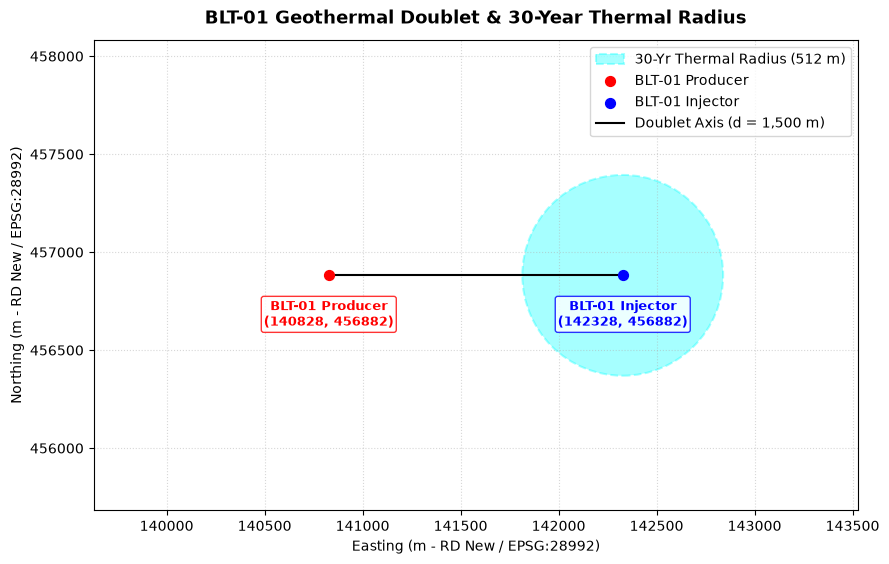

In [27]:
from matplotlib.patches import Circle

# Accurate 30-Year Thermal Radius (R_th)
R_th = np.sqrt((D["Q_m3h"] / 3600) * t * cw_vol / (np.pi * wells_base["BLT-01"]["Thickness"] * caq_vol))
print(f"30-Year Thermal Radius (R_th): {R_th:.1f} meters")

fig, ax = plt.subplots(figsize=(9, 9))

# 30-Year Thermal Radius Circle centered at the Injector
thermal_circle = Circle(
    (inj_x, inj_y), 
    radius=R_th, 
    color='cyan', 
    alpha=0.35, 
    linestyle='--', 
    linewidth=1.5, 
    label=f'30-Yr Thermal Radius ({R_th:.0f} m)'
)
ax.add_patch(thermal_circle)

ax.scatter([prod_x], [prod_y], color='red', s=50, label='BLT-01 Producer', zorder=5)
ax.scatter([inj_x], [inj_y], color='blue', s=50, label='BLT-01 Injector', zorder=5)
ax.plot([prod_x, inj_x], [prod_y, inj_y], color='black', linewidth=1.5, linestyle='-', label='Doublet Axis (d = 1,500 m)')

# Annotations with background boxes
ax.text(prod_x, prod_y - 120, 'BLT-01 Producer\n(140828, 456882)', fontsize=9, ha="center", va='top', fontweight='bold', color='red', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='red'))
ax.text(inj_x, inj_y - 120, 'BLT-01 Injector\n(142328, 456882)', fontsize=9, ha='center', va='top', fontweight='bold', color='blue', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='blue'))

# Map Formatting & Zooming
ax.set_xlim(prod_x - 1200, inj_x + 1200)
ax.set_ylim(prod_y - 1200, prod_y + 1200)
ax.set_title("BLT-01 Geothermal Doublet & 30-Year Thermal Radius", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Easting (m - RD New / EPSG:28992)", fontsize=10)
ax.set_ylabel("Northing (m - RD New / EPSG:28992)", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', frameon=True)
ax.set_aspect('equal')

plt.tight_layout()
fig.savefig(FIG / "BLT-01 thermal radius.png", dpi=200, bbox_inches="tight")
plt.show()

### Cash Flow & LCOE Bar Chart

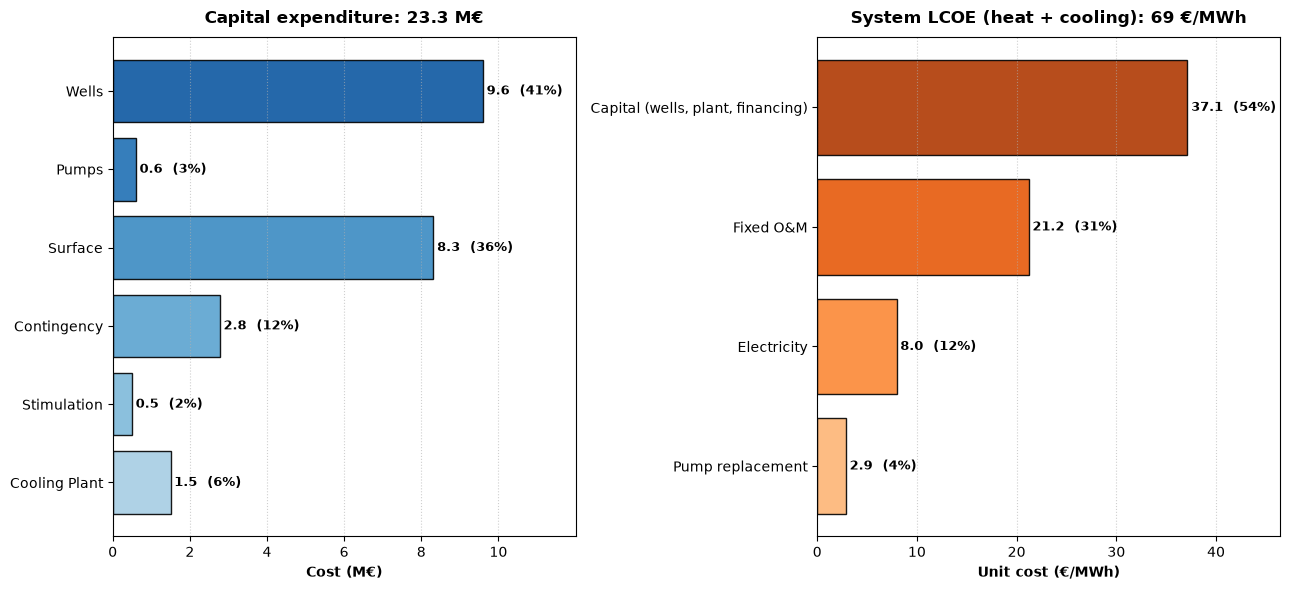

In [28]:
bd = cost_breakdown(D, COST)
capex_components = {k.replace("_", " ").title(): v for k, v in bd["capex_M"].items() if v > 0.005}
lcoe_components = {k: v for k, v in bd["lcoe_split"].items() if v > 0.005}
total_capex, total_lcoe = sum(capex_components.values()), sum(lcoe_components.values())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
for ax, comp, cmap, title, unit, total in [
        (ax1, capex_components, "Blues", f"Capital expenditure: {total_capex:.1f} M€", "Cost (M€)", total_capex),
        (ax2, lcoe_components, "Oranges", f"System LCOE (heat + cooling): {total_lcoe:.0f} €/MWh", "Unit cost (€/MWh)", total_lcoe)]:
    labels, vals = list(comp.keys()), list(comp.values())
    colors = plt.get_cmap(cmap)(np.linspace(0.85, 0.35, len(vals)))
    bars = ax.barh(labels, vals, color=colors, edgecolor="black", alpha=0.9)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel(unit, fontsize=10, fontweight="bold")
    ax.grid(axis="x", linestyle=":", alpha=0.6)
    ax.set_xlim(0, max(vals) * 1.25)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_width() + max(vals) * 0.01, bar.get_y() + bar.get_height() / 2,
                f"{v:.1f}  ({100 * v / total:.0f}%)", va="center", ha="left", fontsize=9, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG / "finances bar chart.png", dpi=200, bbox_inches="tight")
plt.show()